In [1]:
from MultiAgent_DQ import *
import numpy as np
import pandas as pd  
import itertools
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import pandas as pd
import sys
sys.path.append('../')
import tqdm
from utils import *
#TODO run latin hypercube sampling
#TODO: we want to show that for a critical delta and epsilon (delta > delta_c) and (epsilon < epsilon_c), increasing alpha is increasing GT (coop)\n",
#TODO: as alpha goes to 0, the effect of lambda in equilibrium decreases - flattening?\n",
#TODO: refer to face diagram, maximize space, two version: same scale and different scale\n",
#TODO: implement timeout_value/timeout_batch append for value iterations and for batch iterations--> where it stopping? Delta is affecting the reach of the target.
#TODO: nonconv trajectories with vector field (try 0.99 delta and 0.975 for the old algorithm and the new)
#TODO: trajectory analysis
#TODO: add function calculation for ACvsAC
#TODO: have a look just at the IBRG where there is ambuiguity to the equilibria.

## Single Run

In [2]:
break df_f = pd.read_csv("../results/results_from_vectorized_script_raw.csv")

SyntaxError: invalid syntax (3763405797.py, line 1)

In [ ]:
pd.read_csv('./algorithm_results_comparison_test.csv')

,Algorithm,M,alpha,lambda,e,delta,random_uniform,P_AD,P_GT,nonconv,time_max,time_min,time_mean,timeout_out,timeout_vi
0,Algorithm,1,0.01,0.295833,0.042917,0.99,False,1.0,0.0,0,0.472712,0.472712,0.472712,0,0
1,Algorithm_1,1,0.01,0.295833,0.042917,0.99,False,0.0,0.0,1,60.006793,60.006793,60.006793,1,0
2,Algorithm,1,0.01,0.459167,0.042917,0.99,False,0.0,0.0,1,60.029438,60.029438,60.029438,1,0
3,Algorithm_1,1,0.01,0.459167,0.042917,0.99,False,0.0,0.0,1,60.028666,60.028666,60.028666,1,0


In [ ]:
#critical deltas
epsilon_value = 0.1
lambda_value = 0.2
P, R, T, S = 0.2, 0.8, 1, 0
c2 = ((2*P) - (epsilon_value *P) - (epsilon_value *R) - (2 *S) + (epsilon_value *S) + (epsilon_value *T))/((-1 + epsilon_value) *((-2 *P) + (2 *epsilon_value *P) + (2 *S) - (epsilon_value *S) - (epsilon_value *T)))
c1 = (-epsilon_value *P + 2 *R - epsilon_value *R + epsilon_value *S - 2 *T + epsilon_value *T)/((-1 + epsilon_value)* (-2 *P + 2 *epsilon_value *P - epsilon_value *S + 2 *T - epsilon_value *T))
print(f'critical delta 1 is {c1} and critical delta 2 is {c2}')

critical delta 1 is 0.2886002886002886 and critical delta 2 is 0.9661835748792271


In [ ]:
eps, lambda_b, alpha, delta, random_uniform, M_value = 0.1, 0.2,0.1,0.75,False,10

In [ ]:
algo = Algorithm(
        e=eps, lambda_val=lambda_b, alpha=alpha, delta=delta,
        random_uniform=random_uniform, tolerance=1e-5, 
        M=int(M_value), verbose=False
    )
q1_history_per_sample_algo, q2_history_per_sample_algo, batch_times_algo, timeout_out, timeout_vi = algo.run()    

In [ ]:
algo_1 = Algorithm_1(
        e=eps, lambda_val=lambda_b, alpha=alpha, delta=delta,
        random_uniform=random_uniform, tolerance=1e-5, 
        M=int(M_value), verbose=False
    )
q1_history_per_sample_algo1, q2_history_per_sample_algo1, batch_times_algo1, timeout_out_1, timeout_vi_1 = algo_1.run()

## Simulation

In [ ]:
break # For tracking progress
M_value = 100
alpha_values = [0.05,0.1,0.2]
lambda_values = [0.05,0.1,0.2]
delta_values = [0.5,0.6,0.7]  # 1000 equally spaced values from 0 to 0.999
epsilon_values = [0.05,0.1,0.2]  # 1000 equally spaced values from 0 to 0.99
random_uniform_values = [False]

# Store results
results = []

# Generate all parameter combinations
parameter_combinations = list(itertools.product(alpha_values, lambda_values, epsilon_values, delta_values, random_uniform_values))

# Iterate through each parameter combination with tqdm progress bar
for alpha, lambda_val, e, delta, random_uniform in tqdm(parameter_combinations, desc="Processing combinations"):
    # Initialize the algorithm with the current parameter combination
    algo = Algorithm(e=e, lambda_val=lambda_val, 
                     alpha=alpha, delta=delta,
                     random_uniform=random_uniform, tolerance=1e-5, 
                     M=M_value, verbose=False)

    # Run the algorithm
    q1_history_per_sample, q2_history_per_sample = algo.run()

    # Convert results to dataframes
    dfs_1 = convert_dict_to_mean_df(q1_history_per_sample, mean=False)
    dfs_2 = convert_dict_to_mean_df(q2_history_per_sample, mean=False)

    # Initialize strategies played
    strategy_played_1 = {}
    strategy_played_2 = {}

    # Iterate over the dataframe rows
    for i in range(len(dfs_1)):
        last_1 = dfs_1[i].iloc[-1]  # Get the last row using iloc
        last_2 = dfs_2[i].iloc[-1]

        # Define conditions for both players
        GT_1 = (last_1['Q1'] > last_1['Q3']) & (last_1['Q2'] < last_1['Q4'])
        AD_1 = (last_1['Q1'] < last_1['Q3']) & (last_1['Q2'] < last_1['Q4'])
        AC_1 = (last_1['Q1'] > last_1['Q3']) & (last_1['Q2'] > last_1['Q4'])

        GT_2 = (last_2['Q1'] > last_2['Q3']) & (last_2['Q2'] < last_2['Q4'])
        AD_2 = (last_2['Q1'] < last_2['Q3']) & (last_2['Q2'] < last_2['Q4'])
        AC_2 = (last_2['Q1'] > last_2['Q3']) & (last_2['Q2'] > last_2['Q4'])

        # Assign strategy for both players
        strategy_map = {
            AD_1: 1,  # Always Defecting
            GT_1: 2,  # Grim Trigger
            AC_1: 3,  # Always Cooperating
        }

        for player, strategy in [(AD_1, strategy_map), (GT_1, strategy_map), (AC_1, strategy_map)]:
            if player:
                strategy_played_1[i] = strategy[player]
                break

        for player, strategy in [(AD_2, strategy_map), (GT_2, strategy_map), (AC_2, strategy_map)]:
            if player:
                strategy_played_2[i] = strategy[player]
                break

    # Convert strategy_played_1 and strategy_played_2 dictionaries to DataFrames
    df_strategy_1 = pd.DataFrame(list(strategy_played_1.items()), columns=['Index', 'Strategy_1'])
    df_strategy_2 = pd.DataFrame(list(strategy_played_2.items()), columns=['Index', 'Strategy_2'])

    # Merge the two DataFrames on 'Index'
    df_merged = pd.merge(df_strategy_1, df_strategy_2, on='Index')

    # Optionally, set 'Index' as the DataFrame index (if you need it)
    df_merged.set_index('Index', inplace=True)

    # Count how many times Strategy_1 and Strategy_2 are different
    count_diff = (df_merged['Strategy_1'] != df_merged['Strategy_2']).sum()

    # Count how many times both Strategy_1 and Strategy_2 have the value 1
    P_AD = ((df_merged['Strategy_1'] == 1) & (df_merged['Strategy_2'] == 1)).sum() / M_value

    # Count how many times both Strategy_1 and Strategy_2 have the value 2
    P_GT = ((df_merged['Strategy_1'] == 2) & (df_merged['Strategy_2'] == 2)).sum() / M_value

    # Store results for this parameter combination
    results.append({
        'alpha': alpha,
        'lambda': lambda_val,
        'e': e,
        'delta': delta,
        'random_uniform': random_uniform,
        'P_AD': P_AD,
        'P_GT': P_GT,
        'nonconv': count_diff
    })

# Optionally, save results to a file
results_df = pd.DataFrame(results)
results_df.to_csv("results.csv", index=False)


NameError: name 'tqdm' is not defined

## Analysis

In [2]:
df = pd.read_csv("../results/results_from_vectorized_script_raw.csv")
df_fixed = pd.read_csv("../results/results_vect_paramsfixed_time.csv")

In [3]:
df_fixed = df_fixed[df_fixed['lambda']<=0.8]

In [4]:
def round_columns(df, columns, decimals):
    for column in columns:
        df[column] = df[column].round(decimals)
    return df

# Columns to round
columns_to_round = ['delta', 'e', 'lambda', 'alpha']

# Apply the function to df
df = round_columns(df, columns_to_round, 3)
# Apply the function to df_fixed
df_fixed = round_columns(df_fixed, columns_to_round, 3)
df_fixed['M'] = df_fixed['M'].round(0)

In [5]:
columns = ['delta', 'e', 'lambda', 'alpha']

# Generate all pairwise combinations of the columns
pair_combinations = list(itertools.combinations(columns, 2))

# Display the pair combinations
print(pair_combinations)

[('delta', 'e'), ('delta', 'lambda'), ('delta', 'alpha'), ('e', 'lambda'), ('e', 'alpha'), ('lambda', 'alpha')]


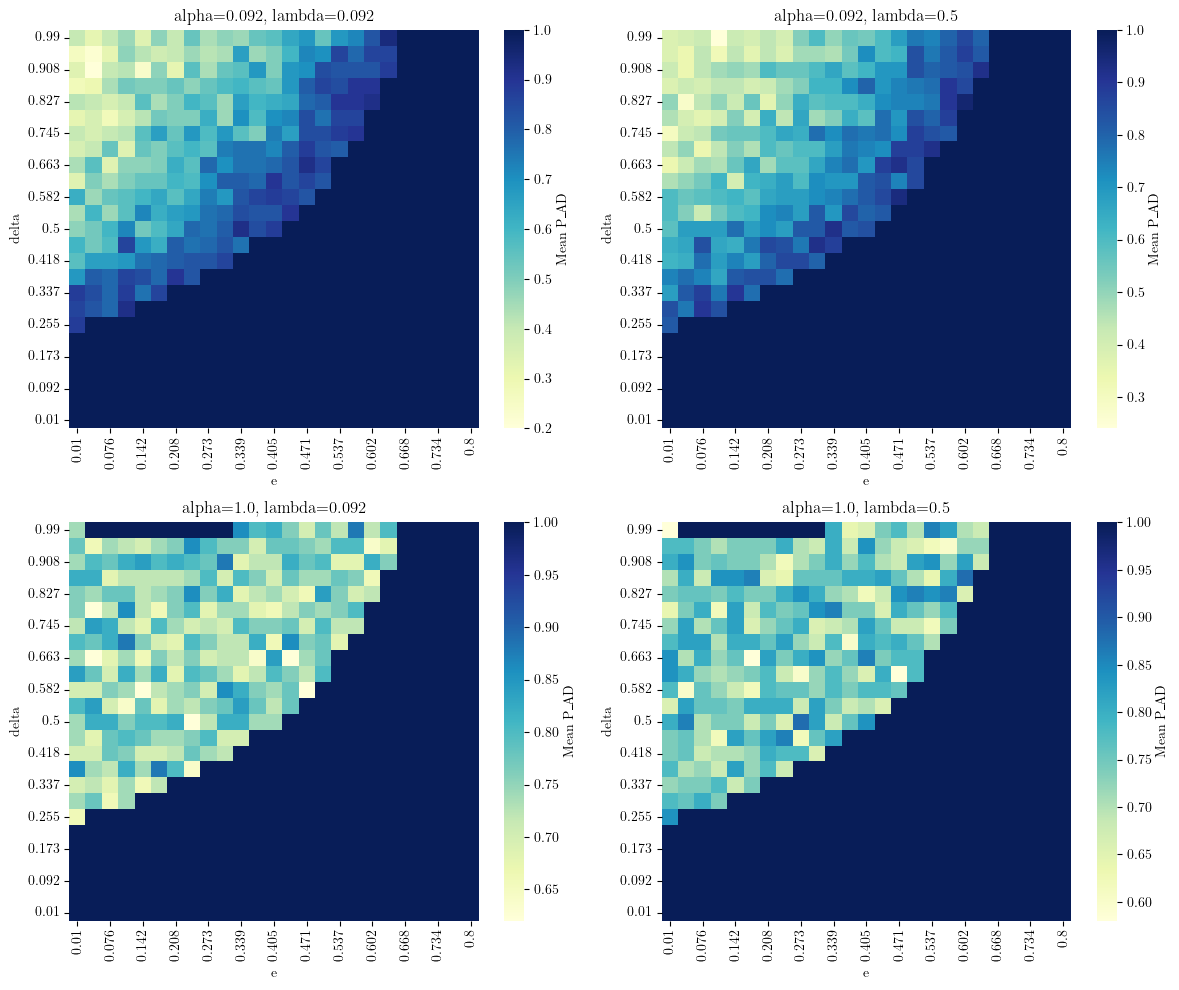

In [6]:
def heatmap_fixed_pairs(df, yaxis, xaxis, value, fixed_pairs):
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))  # Create a 2x2 grid for subplots
    axes = axes.flatten()  # Flatten the array for easy indexing

    for i, (alpha_val, lambda_val) in enumerate(fixed_pairs):
        ax = axes[i]

        # Filter data for the specific (alpha, lambda) pair
        filtered_df = df[(df['alpha'] == alpha_val) & (df['lambda'] == lambda_val)]

        if filtered_df.empty:
            ax.set_title(f'No data for alpha={alpha_val}, lambda={lambda_val}')
            ax.axis('off')  # Hide axes if no data
            continue

        # Create the heatmap
        heatmap_data = filtered_df.pivot_table(index=yaxis, columns=xaxis, values=value, aggfunc='mean')
        sns.heatmap(heatmap_data, cmap='YlGnBu', annot=False, fmt='.2f', 
                    cbar_kws={'label': f'Mean {value}'}, ax=ax)

        # Titles and labels
        ax.set_title(f'alpha={alpha_val}, lambda={lambda_val}')
        ax.set_xlabel(xaxis)
        ax.set_ylabel(yaxis)
        ax.invert_yaxis()

    plt.tight_layout()
    plt.show()

#TODO: face diagram dynamic with different values of alpha and lambda (nice pairs = [ (0.1, 0.1) (0.1, 0.5)  (1, 0.1) (1, 0.5) ]
fixed_pairs = [(0.092, 0.092), (0.092, 0.5), (1., 0.092), (1., 0.5)]
heatmap_fixed_pairs(df, 'delta', 'e', 'P_AD', fixed_pairs)


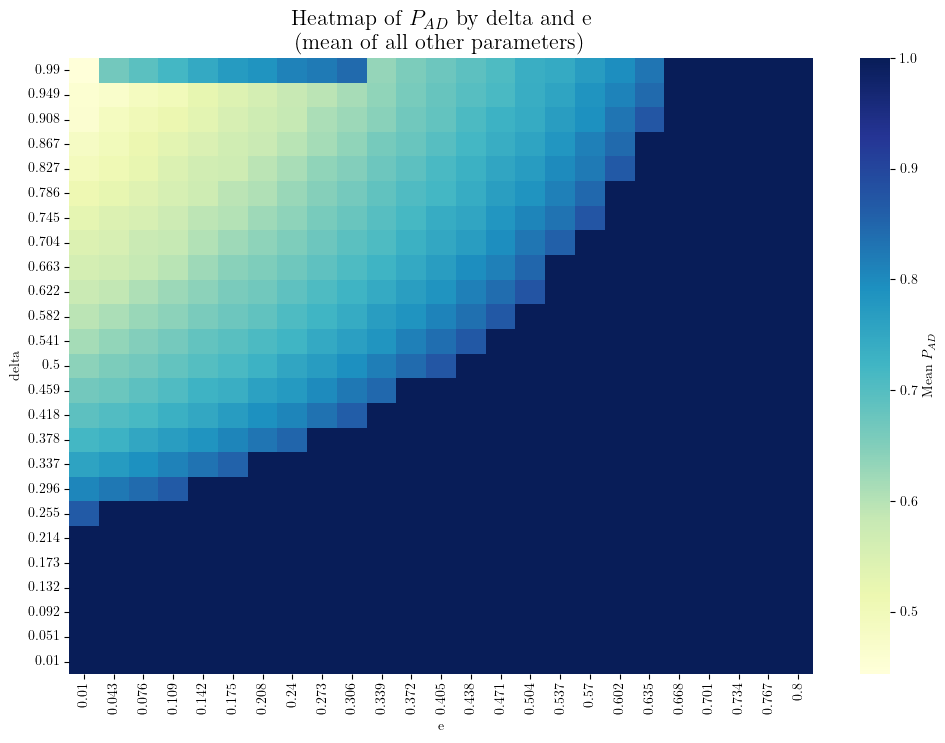

In [7]:
heatmap_mean(df, 'delta', 'e', 'P_AD')
#heatmap_mean(df, 'delta', 'lambda','P_AD')
#heatmap_mean(df, 'delta', 'alpha', 'P_AD')
#heatmap_mean(df, 'e', 'lambda', 'P_AD')
#heatmap_mean(df, 'e', 'alpha', 'P_AD')
#heatmap_mean(df, 'lambda', 'alpha', 'P_AD')

In [10]:
#TODO: as alpha goes to 0, the effect of lambda in equilibrium decreases - flattening?
m = 5000

In [8]:

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.cm as cm

import seaborn as sns
import matplotlib as mpl

# Use LaTeX for text rendering
mpl.rcParams['text.usetex'] = True
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['text.latex.preamble'] = r'\usepackage{amsmath}'
def plot_multiple_panels(df, param_sets, x_var, varying_var, y_var, m, use_same_scale=True):
    """
    Plots multiple subplots with a single shared legend.

    Parameters:
    - df: DataFrame containing the data.
    - param_sets: List of dictionaries with fixed parameter values for each subplot.
    - x_var: The variable to be plotted on the x-axis.
    - varying_var: The variable that varies across lines.
    - y_var: The variable to plot on the y-axis ("P_GT" or "P_AD").
    - m: Fixed value for 'M', added to all parameter sets.
    - use_same_scale: If True, all subplots share the same y-axis limits.
    """

    if y_var not in df.columns:
        raise ValueError(f"The specified y-axis variable '{y_var}' is not in the dataframe.")

    y_limits = (-0.1, 0.7) if use_same_scale else None

    # Adjust subplot spacing based on scale setting
    wspace, hspace = (0.02, 0.15) if use_same_scale else (0.2, 0.2)

    fig, axes = plt.subplots(3, 3, figsize=(12, 8), 
                             gridspec_kw={'wspace': wspace, 'hspace': hspace}, 
                             constrained_layout=False)
    axes = axes.flatten()
    
    handles, labels = None, None

    for i, fixed_vars in enumerate(param_sets):
        fixed_vars['M'] = m
        handles, labels = plot_analysis_multiple_lines_sub(df, fixed_vars, x_var, varying_var, y_var, axes[i], y_limits)

    # Add a single legend outside the plot
    if handles and labels:
        fig.legend(handles, labels, title=varying_var, loc='upper right', bbox_to_anchor=(1.1, 1))

    # Adjust axis labels based on `use_same_scale`
    if use_same_scale:
        for ax in axes:
            ax.label_outer()  # Hide inner labels
    else:
        for ax in axes:
            ax.set_ylabel(y_var)  # Always show y-axis
        for ax in axes[:-3]:  # Hide x-axis labels for the first two rows
            ax.set_xticklabels([])
            ax.set_xlabel('')  # Show y-axis for each plot

    plt.show()

def plot_analysis_multiple_lines_sub(df, fixed_vars, x_var, varying_var, y_var, ax, y_limits=None):
    """
    Plots multiple lines in a single subplot without adding a legend.
    
    Parameters:
    - df: DataFrame containing the data.
    - fixed_vars: Dictionary of fixed variables.
    - x_var: Variable for the x-axis.
    - varying_var: Variable to vary across lines.
    - y_var: Variable for the y-axis.
    - ax: Matplotlib axis.
    - y_limits: Tuple for y-axis limits.
    """
    
    if y_var not in df.columns:
        raise ValueError(f"The dataframe must contain the column '{y_var}' for plotting.")
    
    filtered_df = df.copy()
    for var, value in fixed_vars.items():
        filtered_df = filtered_df[filtered_df[var] == value]
    
    if filtered_df.empty:
        return None, None

    unique_values = sorted(filtered_df[varying_var].unique())    
    norm = plt.Normalize(min(unique_values), max(unique_values))
    cmap = cm.get_cmap('viridis')

    handles, labels = [], []

    for value in unique_values:
        subset = filtered_df[filtered_df[varying_var] == value]
        if not subset.empty:
            line, = ax.plot(
                subset[x_var], subset[y_var], marker='o', 
                label=f"{varying_var}={value:.3f}", color=cmap(norm(value))
            )
            handles.append(line)
            labels.append(f"{varying_var}={value:.3f}")

    ax.set_title(f"Fixed: " + ", ".join(f"{k}={v}" for k, v in fixed_vars.items() if k != 'M'))
    ax.set_xlabel(x_var)
    ax.grid()

    if y_limits:
        ax.set_ylim(y_limits)

    return handles, labels


## TODO: refer to face diagram, maximize space, two version: same scale and different scale

/var/folders/03/nmmsz83d1rv4p3r0pt47s6ww0000gp/T/ipykernel_25900/2752857488.py:88: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('viridis')


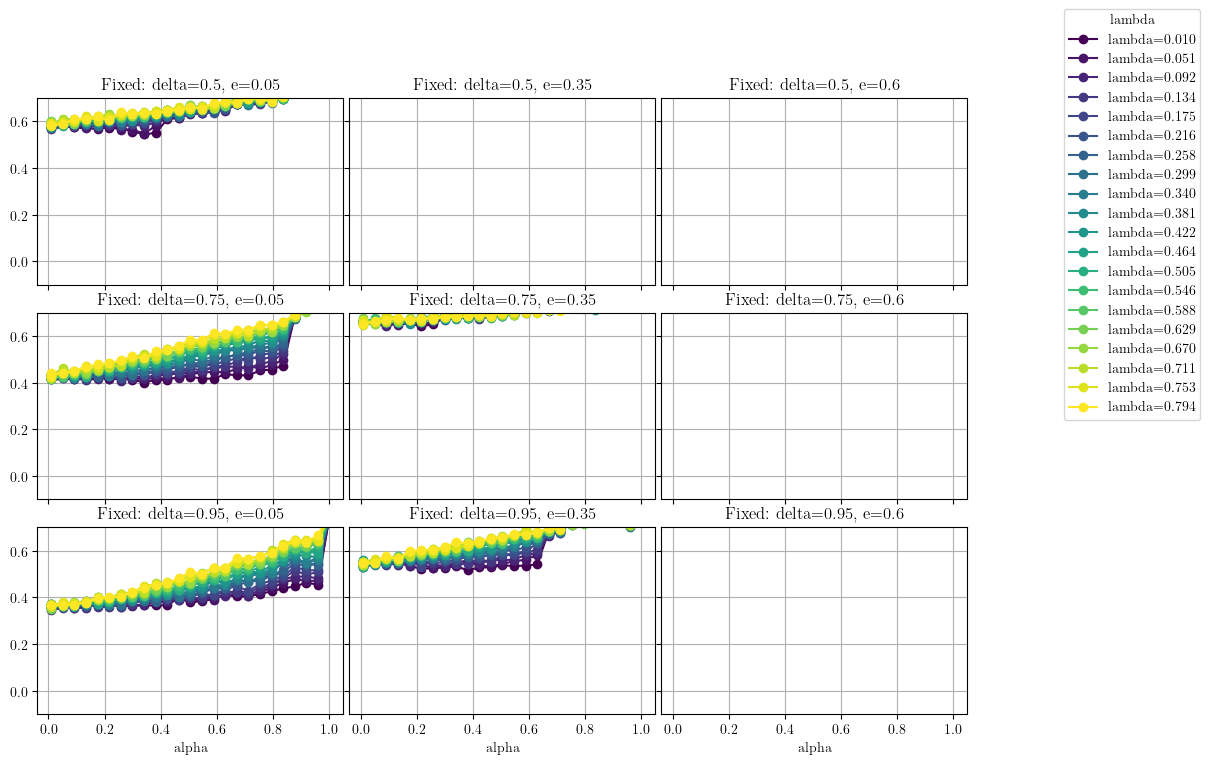

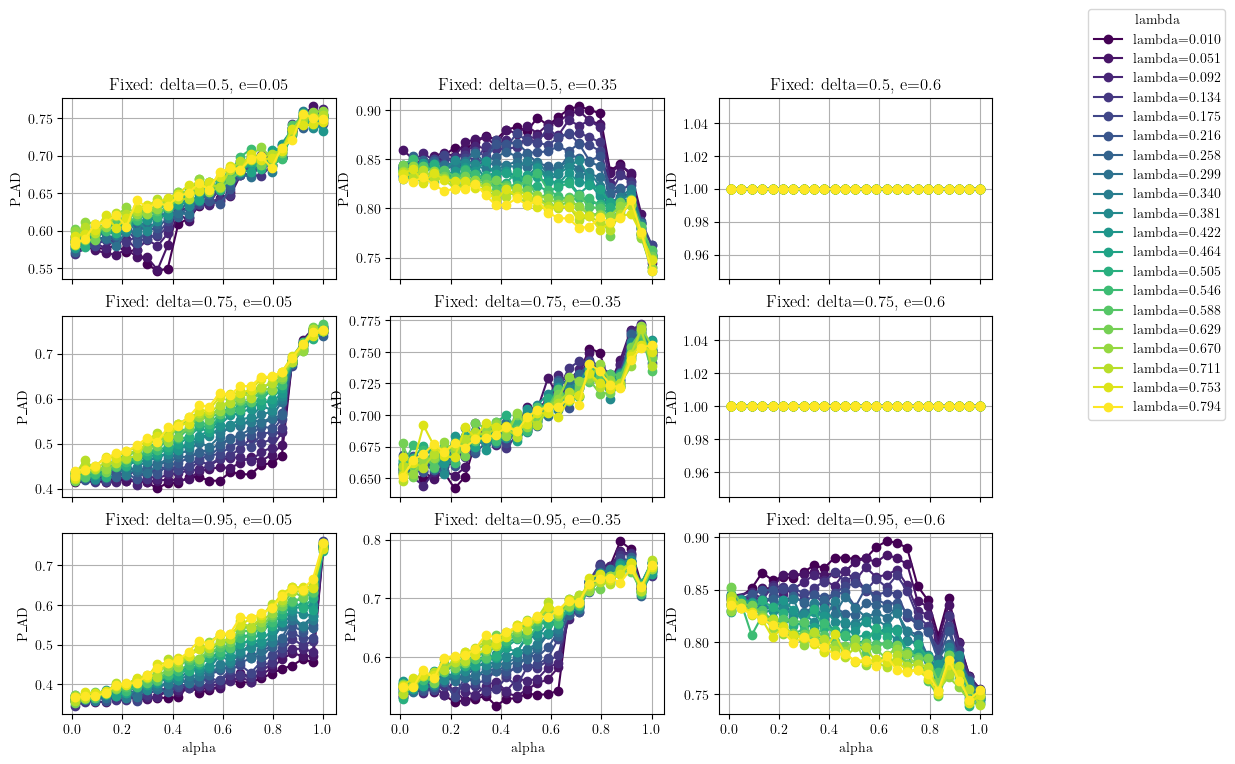

/var/folders/03/nmmsz83d1rv4p3r0pt47s6ww0000gp/T/ipykernel_25900/2752857488.py:88: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('viridis')


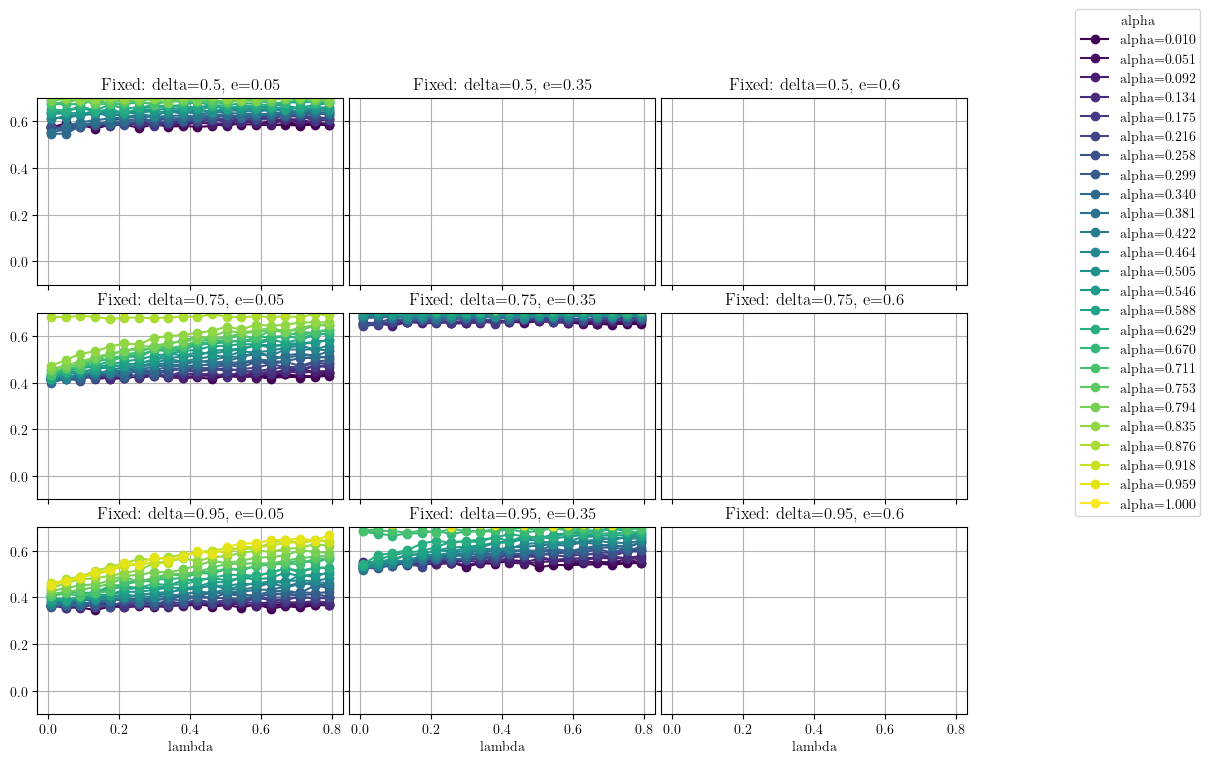

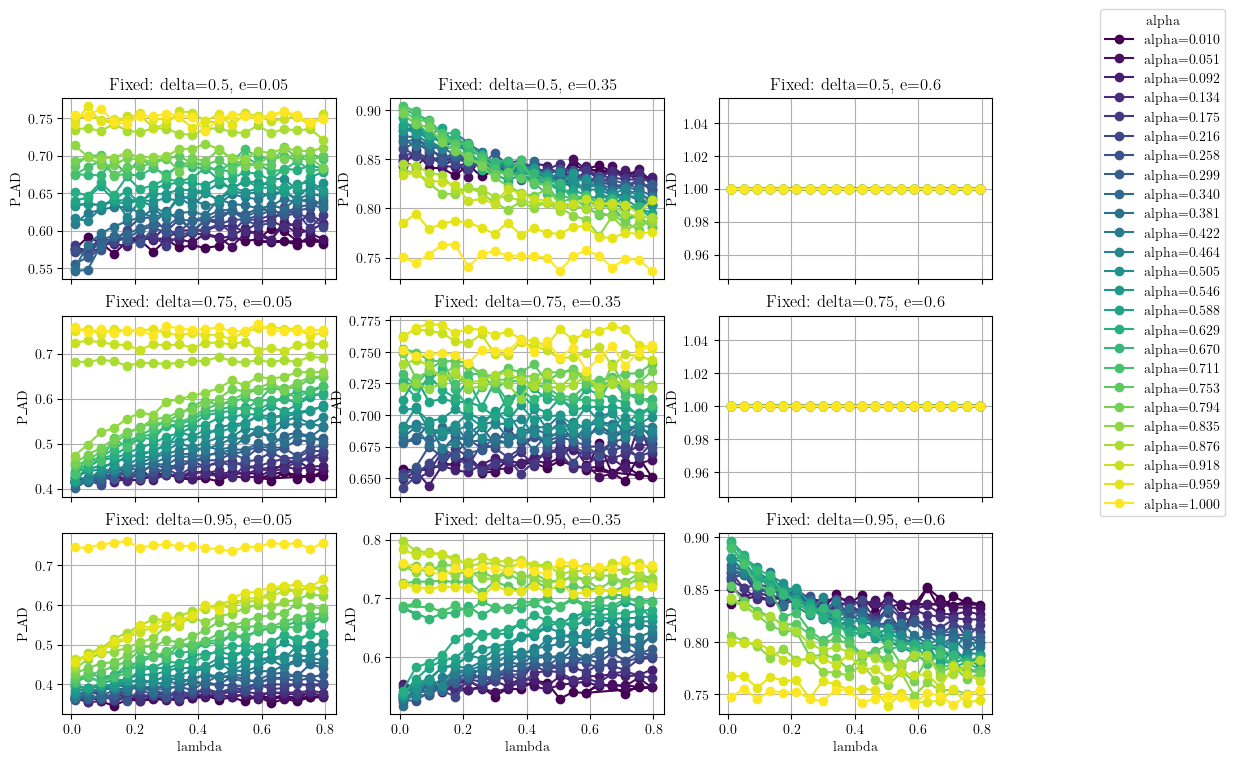

In [11]:
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.35},
    {'delta': 0.5, 'e': 0.6},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.35},
    {'delta': 0.75, 'e': 0.6},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.35},
    {'delta': 0.95, 'e': 0.6}
]

m=5000
y = 'P_AD'
plot_multiple_panels(df_fixed, param_sets, x_var="alpha", varying_var="lambda", y_var=y, m=5000, use_same_scale=True)
plot_multiple_panels(df_fixed, param_sets, x_var="alpha", varying_var="lambda", y_var=y, m=5000, use_same_scale=False)
plot_multiple_panels(df_fixed, param_sets, x_var="lambda", varying_var="alpha", y_var=y, m=5000, use_same_scale=True)
plot_multiple_panels(df_fixed, param_sets, x_var="lambda", varying_var="alpha", y_var=y, m=5000, use_same_scale=False)

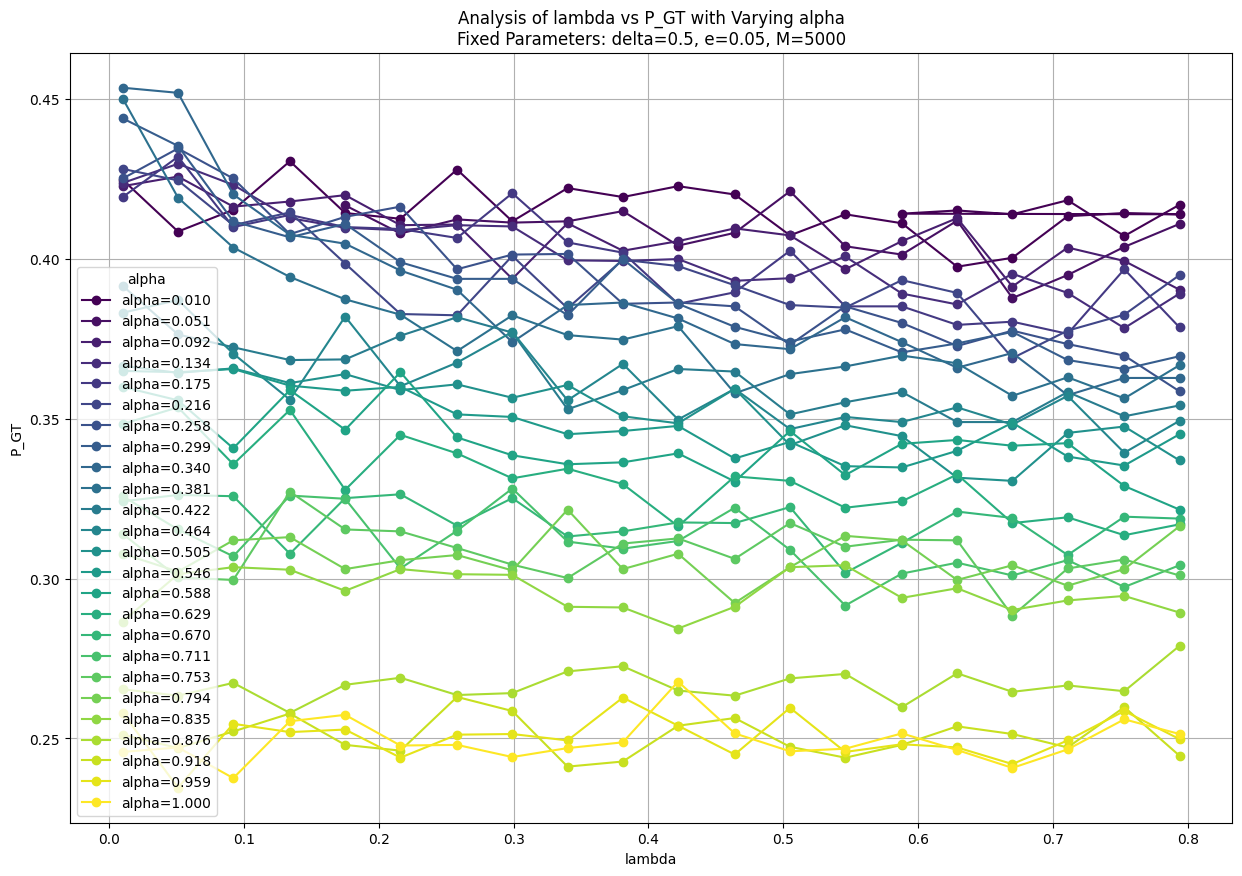

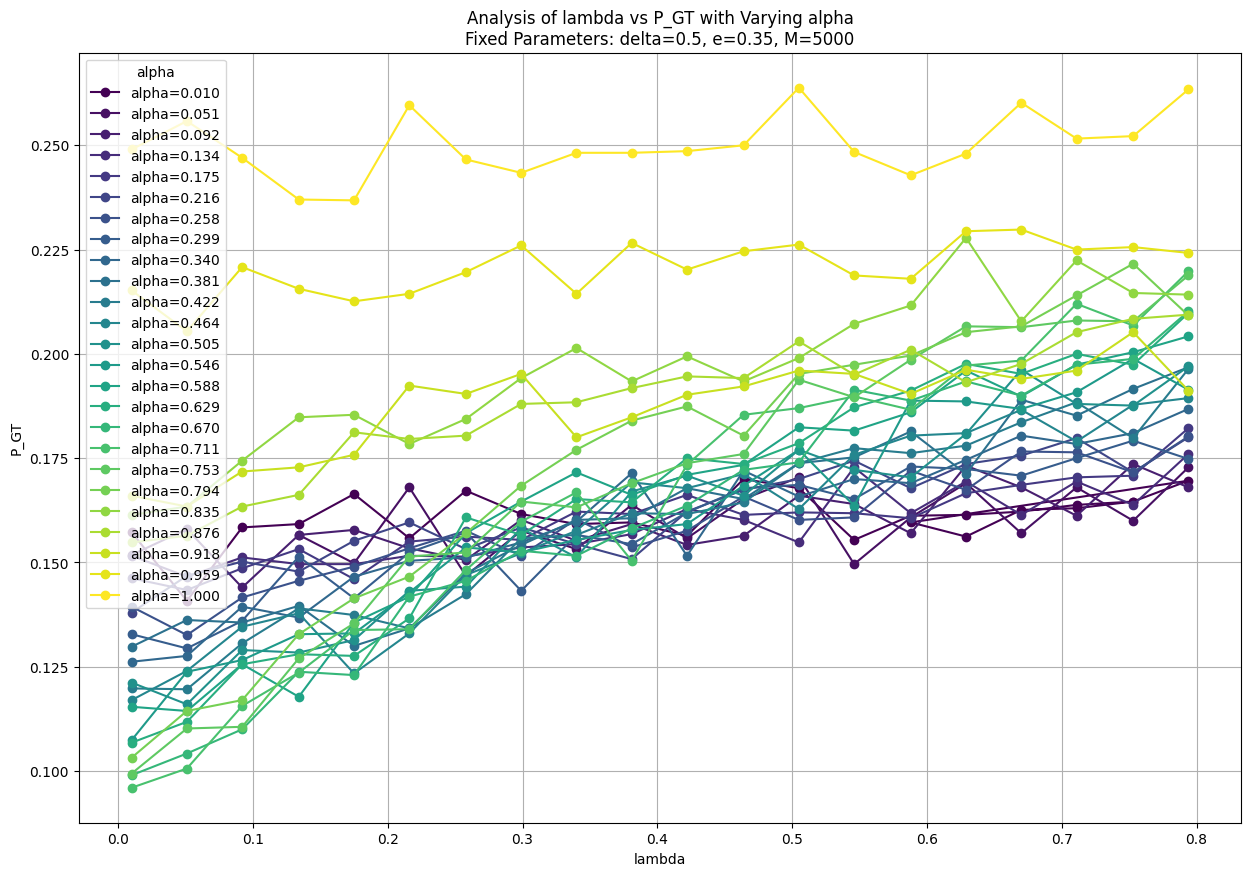

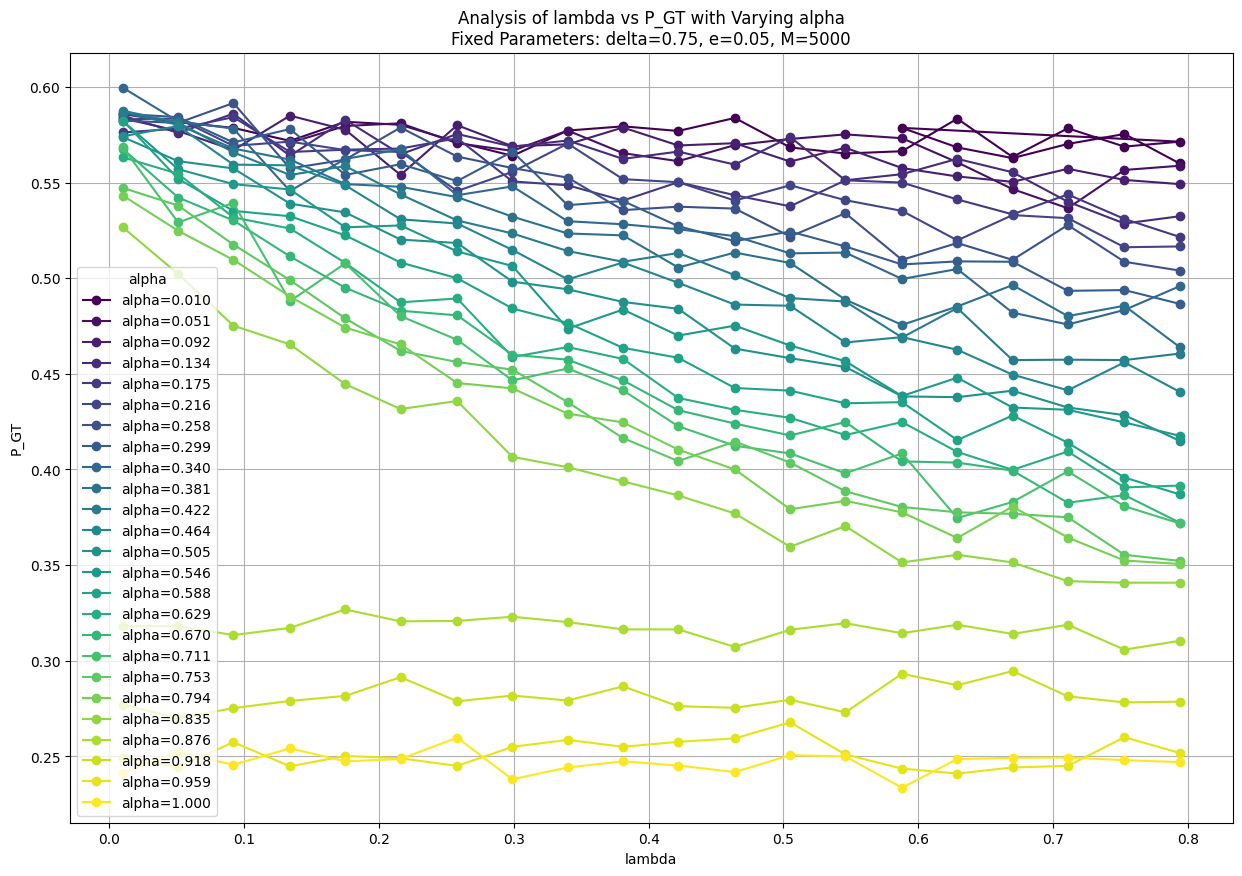

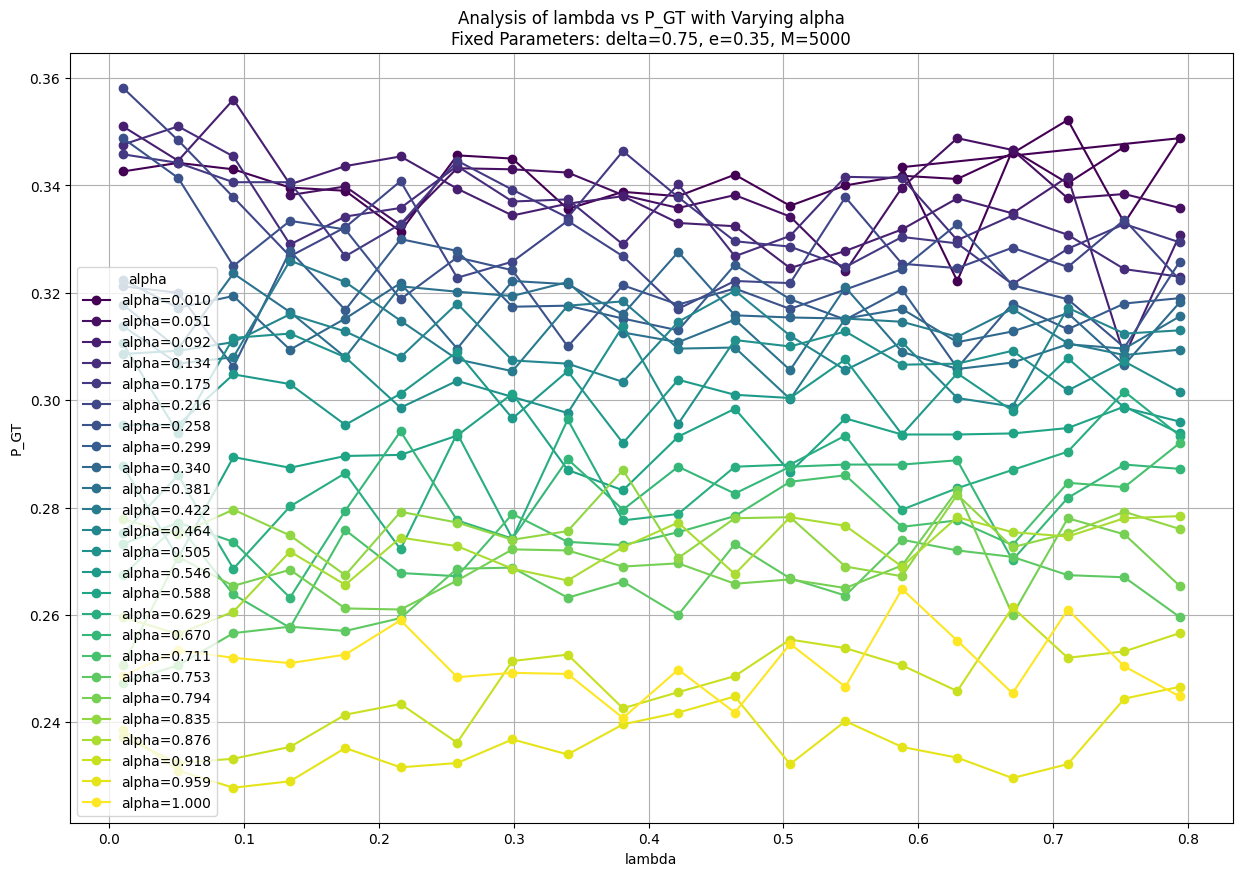

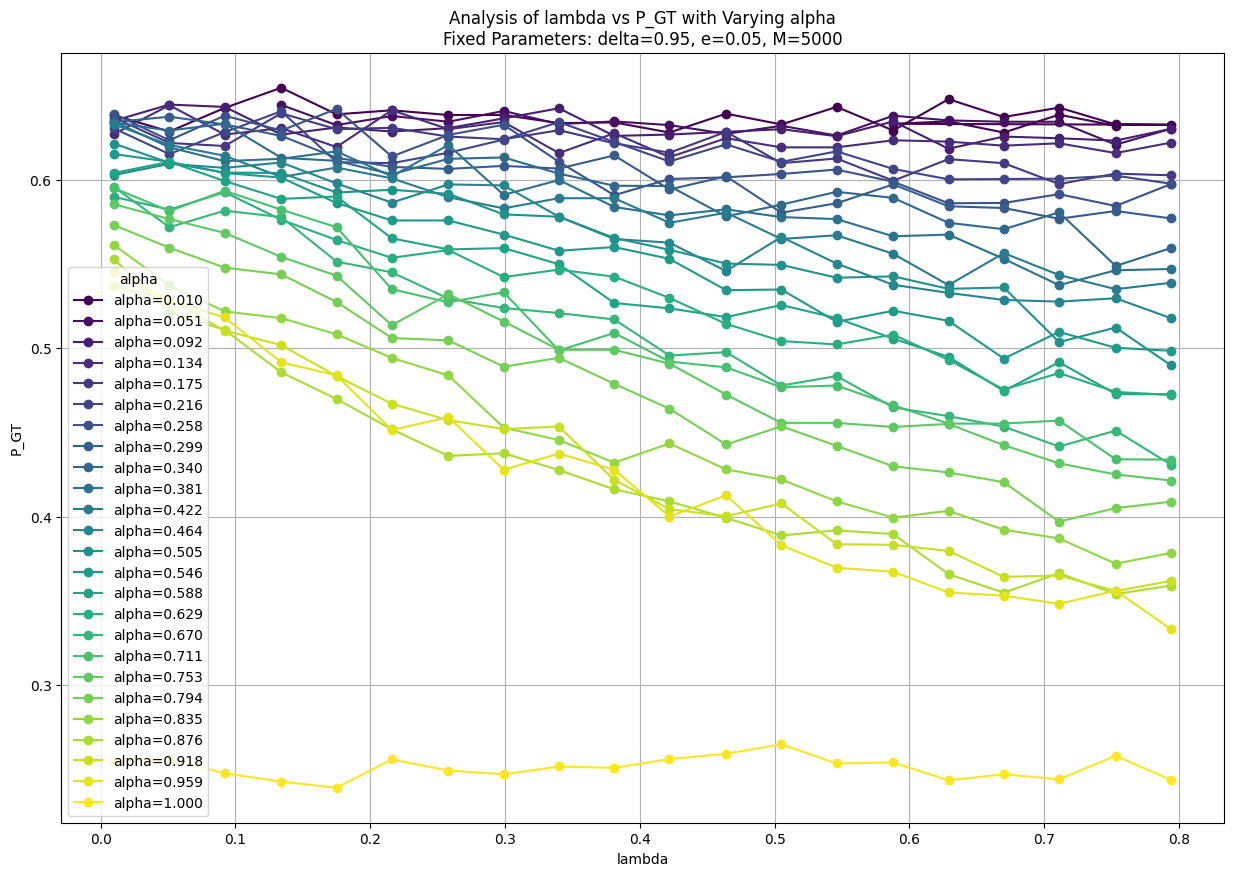

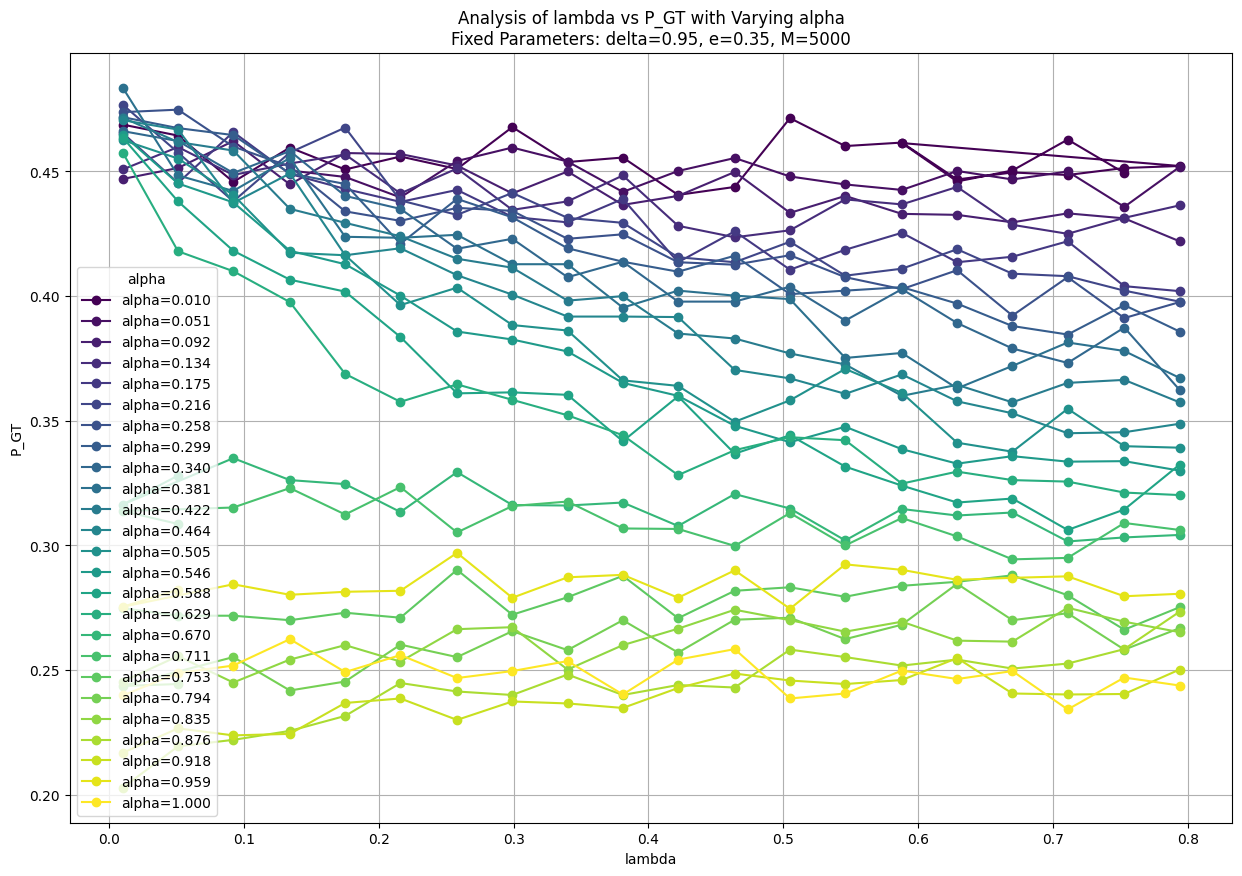

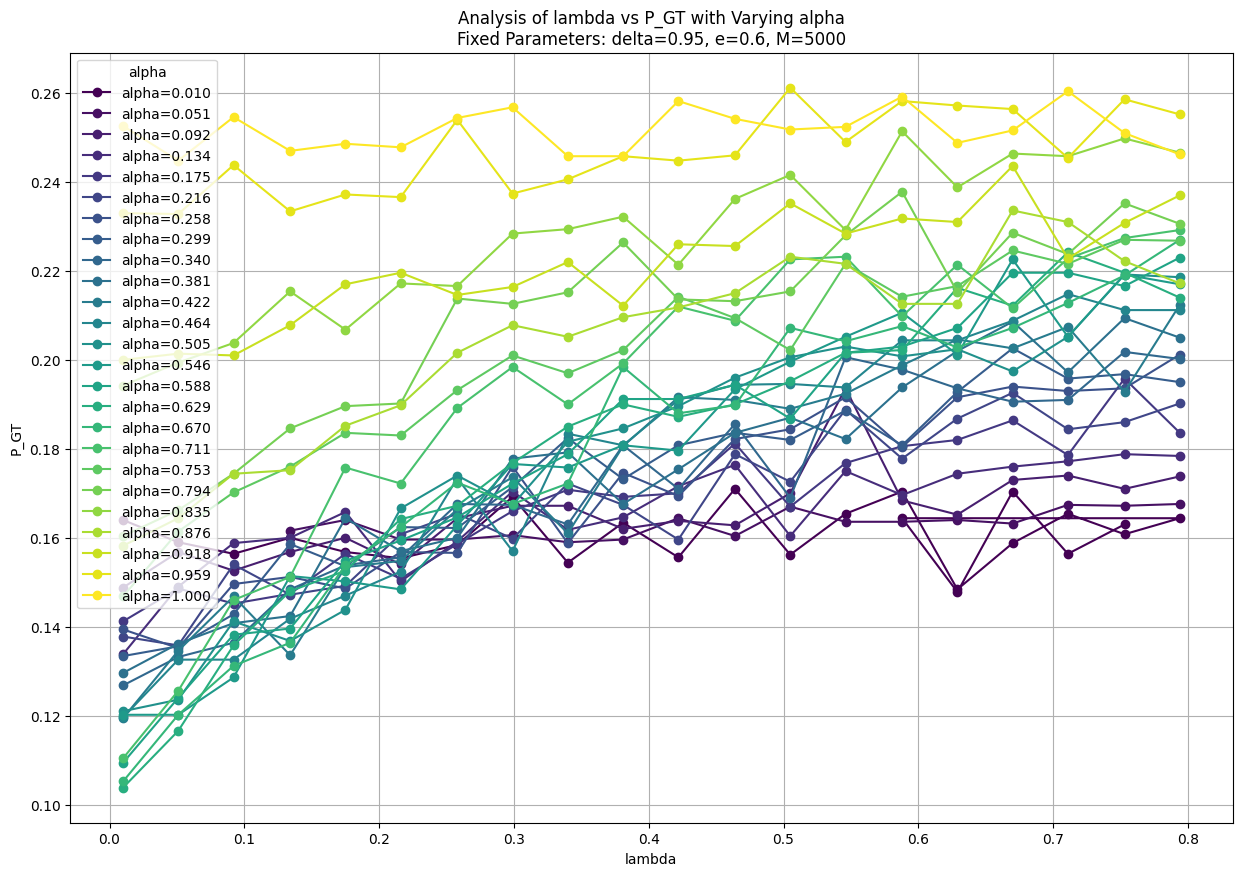

In [13]:
plot_analysis_multiple_lines(
    df=df_fixed, 
    fixed_vars={'delta': 0.5, 'e': 0.05, 'M': m}, 
    x_var='lambda', 
    varying_var='alpha'
)
plot_analysis_multiple_lines(
    df=df_fixed, 
    fixed_vars={'delta': 0.5, 'e': 0.35, 'M': m}, 
    x_var='lambda', 
    varying_var='alpha'
)

plot_analysis_multiple_lines(
    df=df_fixed, 
    fixed_vars={'delta': 0.75, 'e': 0.05, 'M': m}, 
    x_var='lambda', 
    varying_var='alpha'
)
plot_analysis_multiple_lines(
    df=df_fixed, 
    fixed_vars={'delta': 0.75, 'e': 0.35, 'M': m}, 
    x_var='lambda', 
    varying_var='alpha'
)

plot_analysis_multiple_lines(
    df=df_fixed, 
    fixed_vars={'delta': 0.95, 'e': 0.05, 'M': m}, 
    x_var='lambda', 
    varying_var='alpha'
)
plot_analysis_multiple_lines(
    df=df_fixed, 
    fixed_vars={'delta': 0.95, 'e': 0.35, 'M': m}, 
    x_var='lambda', 
    varying_var='alpha'
)
plot_analysis_multiple_lines(
    df=df_fixed, 
    fixed_vars={'delta': 0.95, 'e': 0.6, 'M': m}, 
    x_var='lambda', 
    varying_var='alpha'
)

<Axes: >

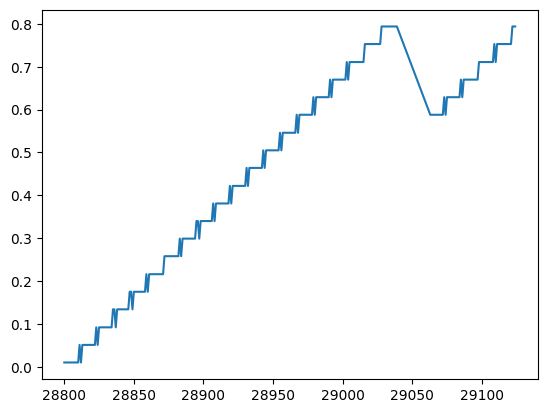

In [14]:
df_fixed[(df_fixed['M'] == 5000)& (df_fixed['alpha'] == 0.01 )]['lambda'].plot()

## TIME ANALYSIS

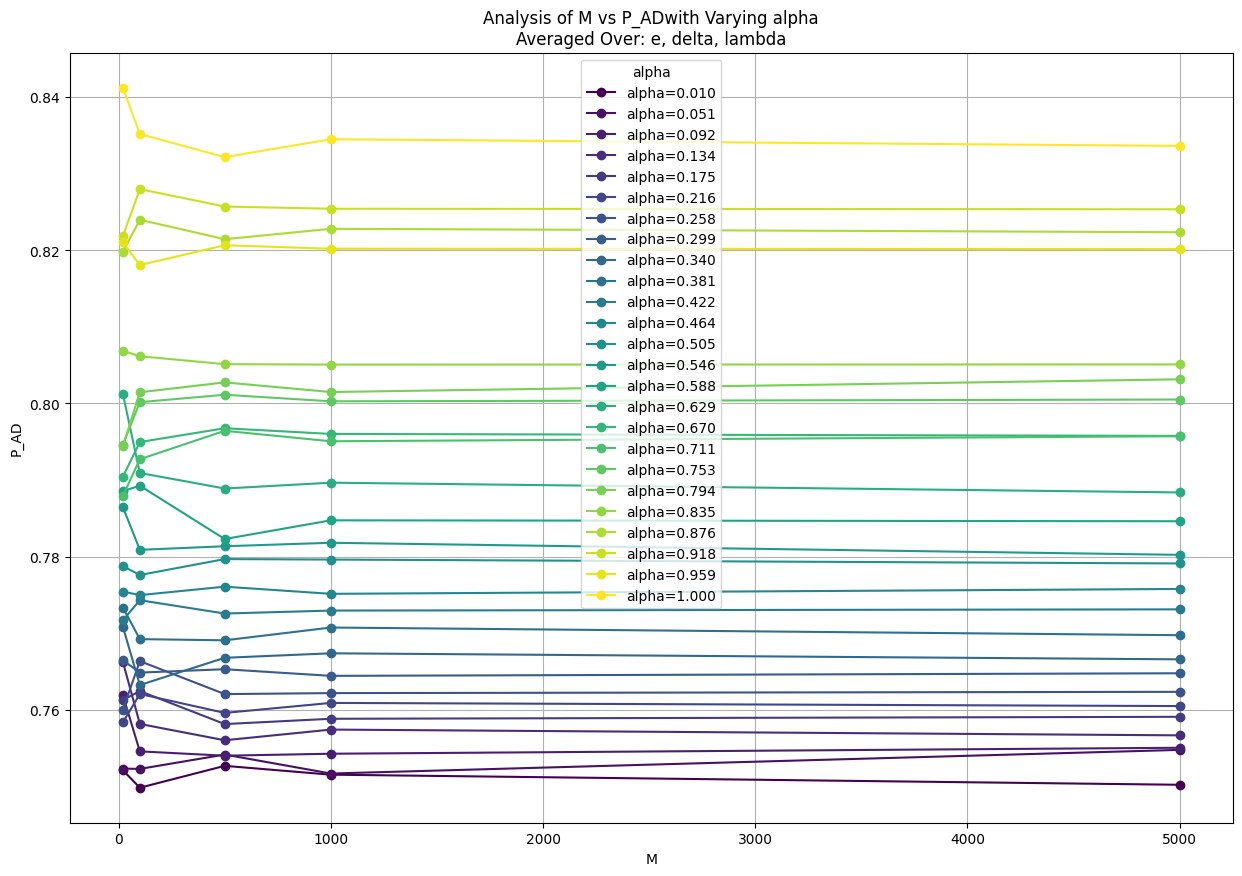

In [15]:
plot_analysis_average_and_vary(
    df=df_fixed, 
    y_var='P_AD',
    averaging_vars=['e', 'delta', 'lambda'], 
    x_var='M', 
    varying_var='alpha'
)

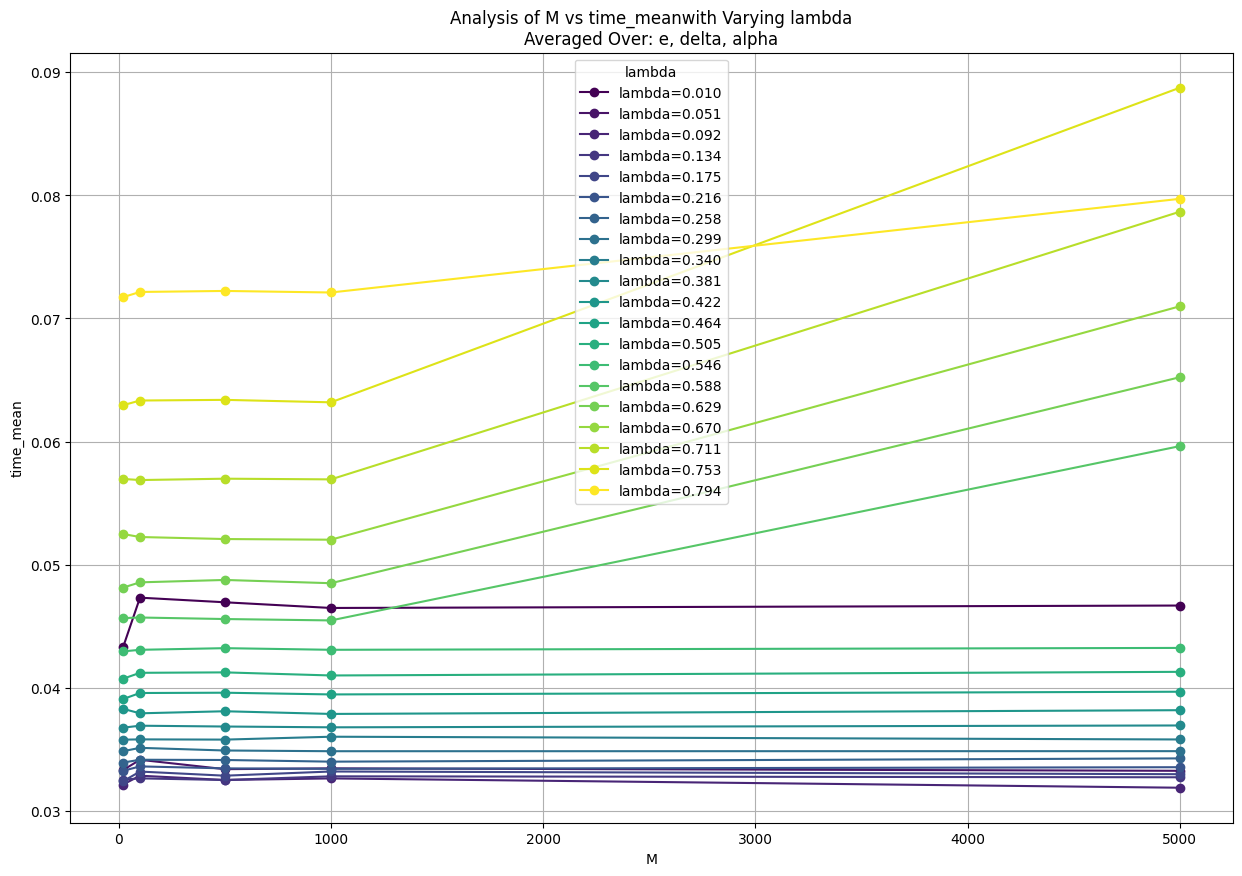

In [16]:
plot_analysis_average_and_vary(
    df=df_fixed, 
    y_var='time_mean',
    averaging_vars=['e', 'delta', 'alpha'], 
    x_var='M', 
    varying_var='lambda'
)

In [17]:
a = 0.010


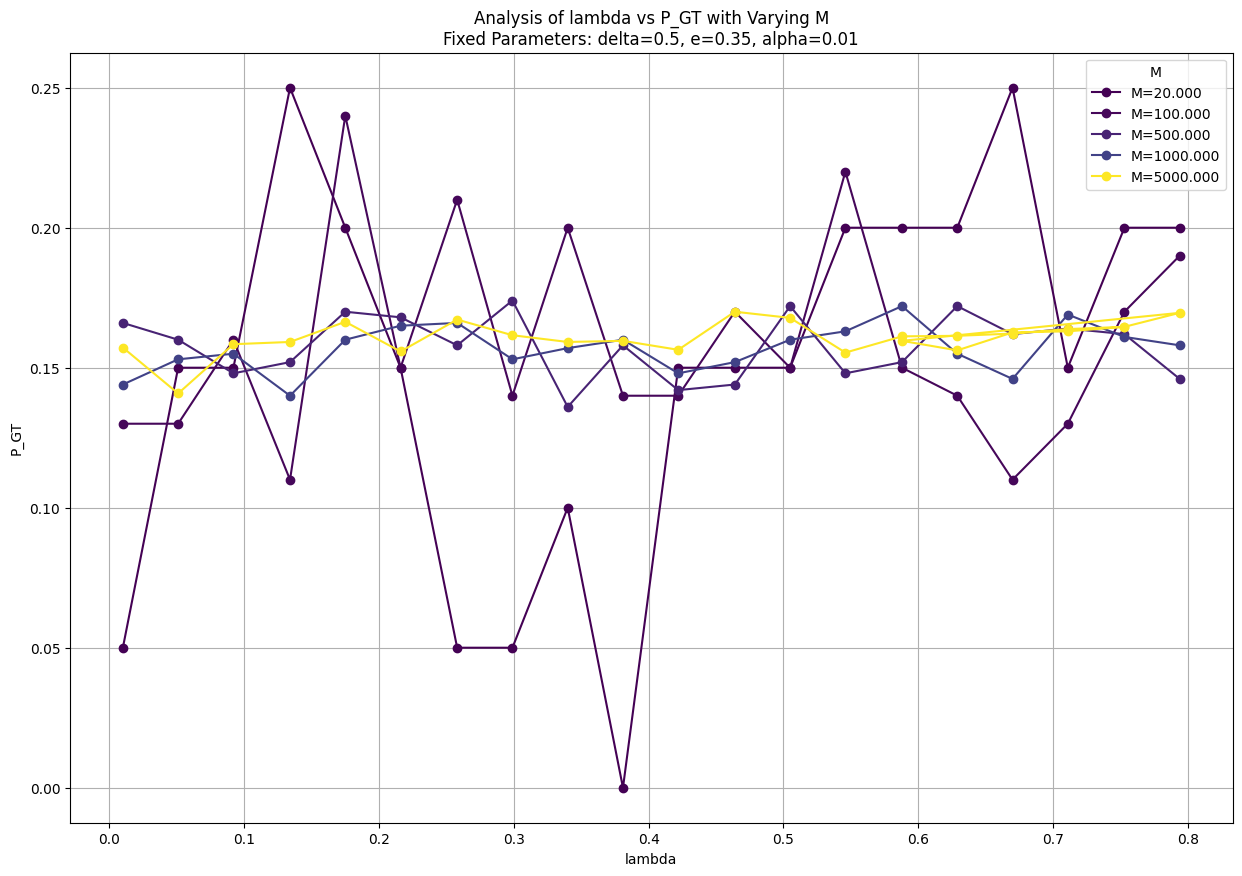

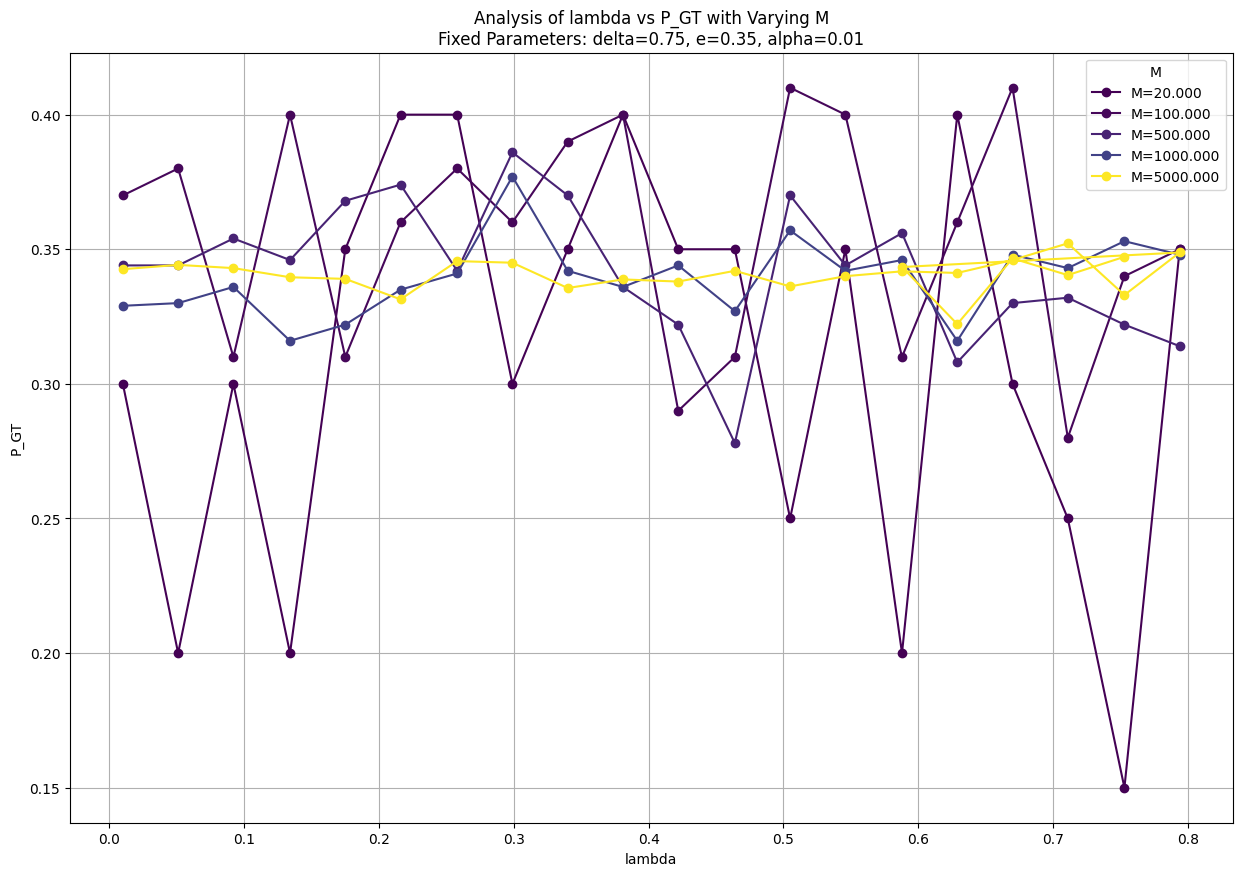

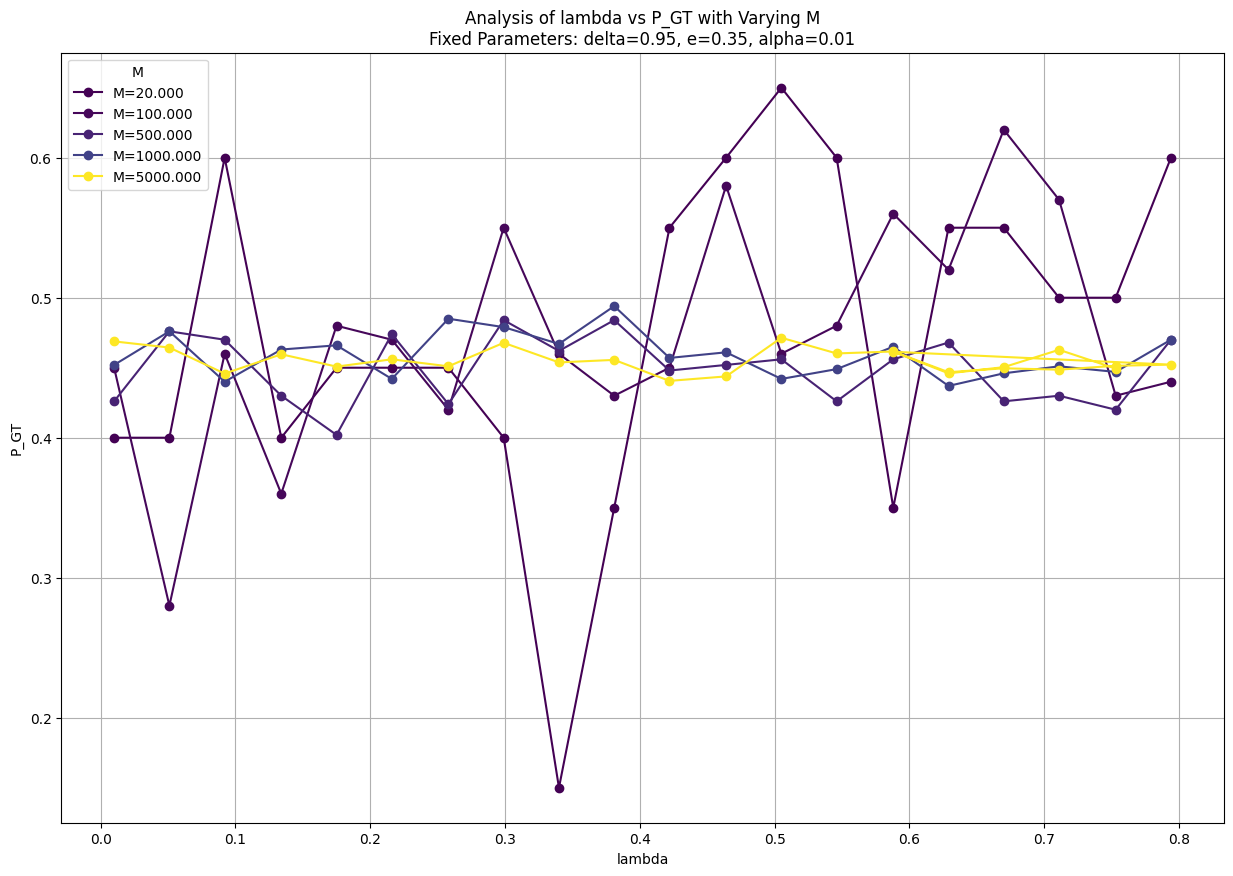

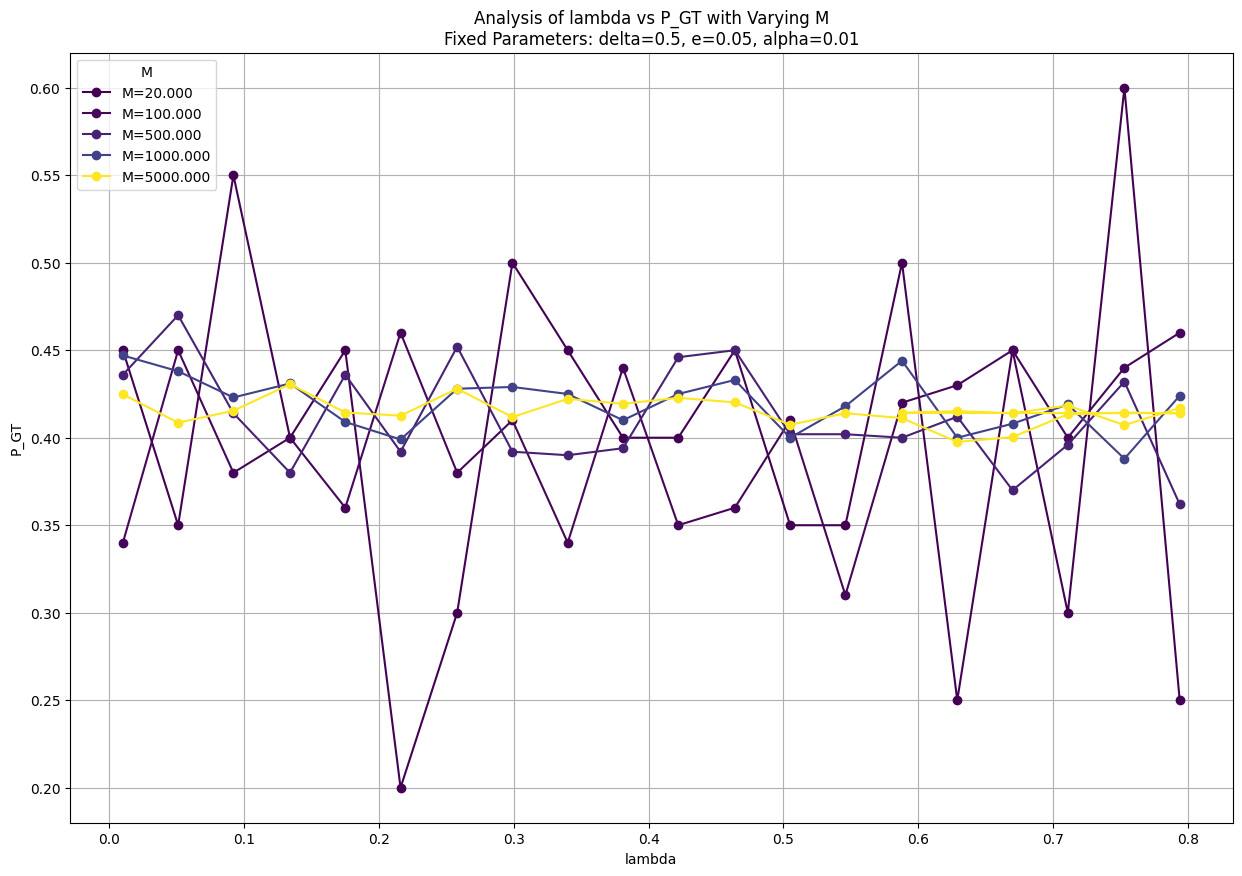

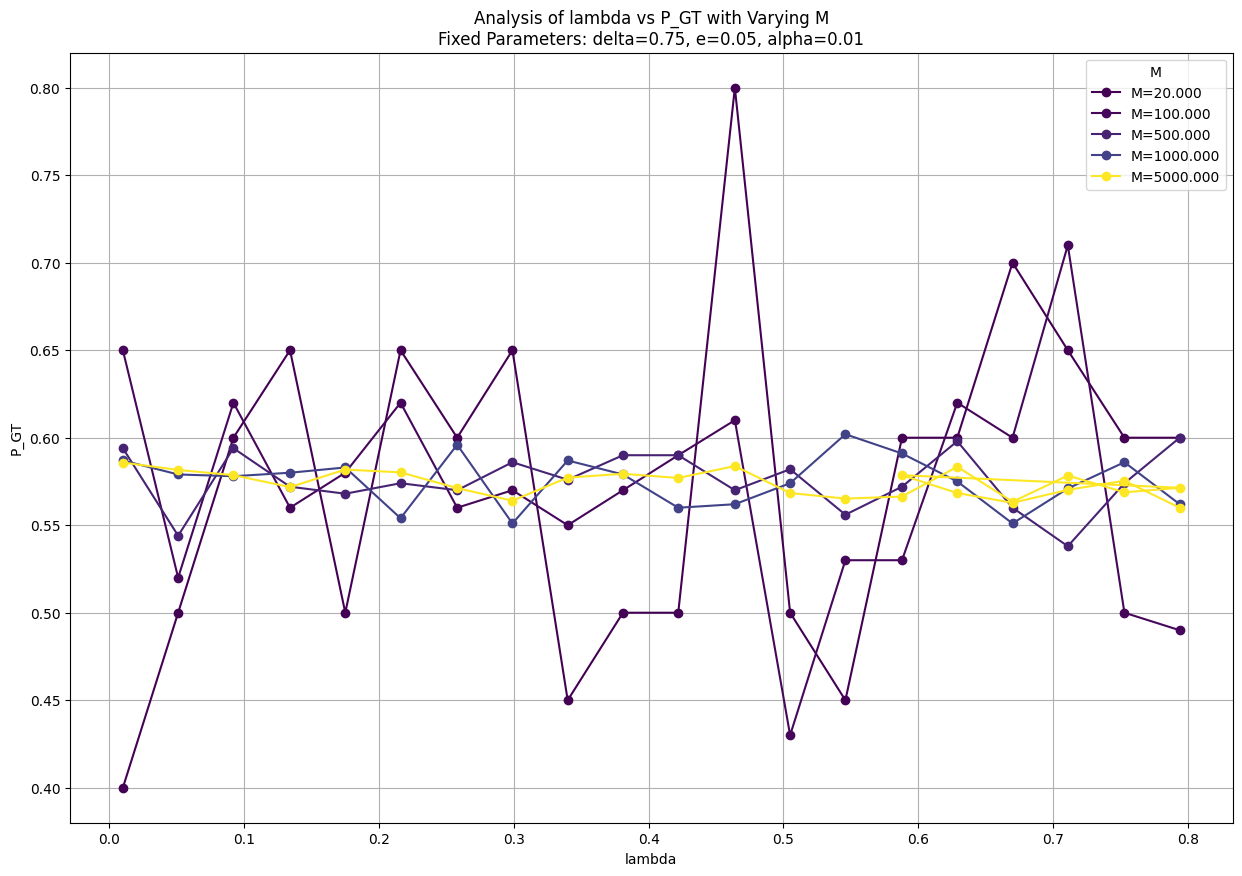

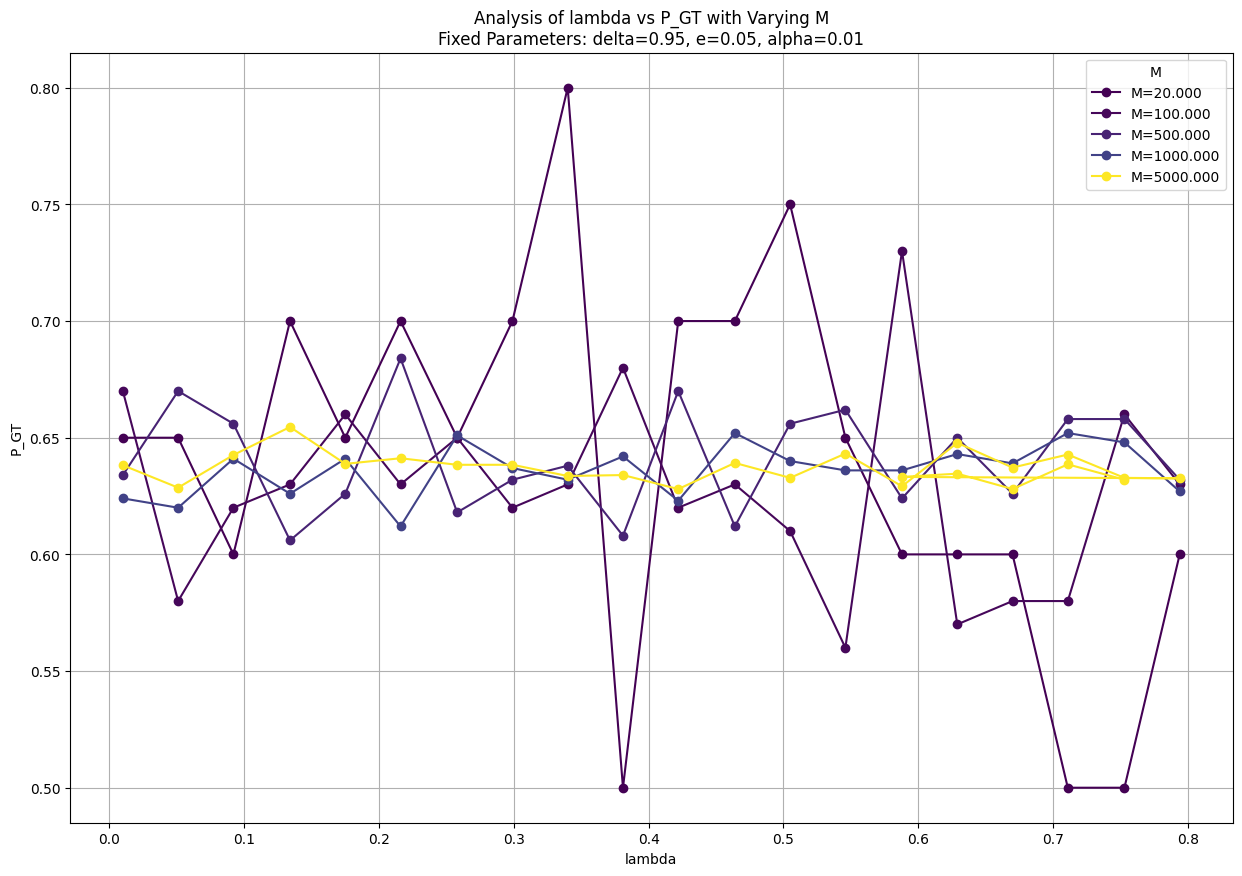

In [18]:
plot_analysis_multiple_lines(
    df=df_fixed, 
    fixed_vars={'delta': 0.5, 'e': 0.35, 'alpha': a}, 
    x_var='lambda', 
    varying_var='M'
)
plot_analysis_multiple_lines(
    df=df_fixed, 
    fixed_vars={'delta': 0.75, 'e': 0.35, 'alpha': a}, 
    x_var='lambda', 
    varying_var='M'
)
plot_analysis_multiple_lines(
    df=df_fixed, 
    fixed_vars={'delta': 0.95, 'e': 0.35, 'alpha': a}, 
    x_var='lambda', 
    varying_var='M'
)
plot_analysis_multiple_lines(
    df=df_fixed, 
    fixed_vars={'delta': 0.5, 'e': 0.05, 'alpha': a}, 
    x_var='lambda', 
    varying_var='M'
)
plot_analysis_multiple_lines(
    df=df_fixed, 
    fixed_vars={'delta': 0.75, 'e': 0.05, 'alpha': a}, 
    x_var='lambda', 
    varying_var='M'
)
plot_analysis_multiple_lines(
    df=df_fixed, 
    fixed_vars={'delta': 0.95, 'e': 0.05, 'alpha': a}, 
    x_var='lambda', 
    varying_var='M'
)